# Introducción a Python para datos geoespaciales

**Pregunta guía:** ¿por qué programar si puedo ver las imágenes en el navegador?

Este notebook repasa, con ejemplos que puedes ejecutar y modificar, lo básico de Python que necesitas para trabajar con datos de un lote. Al final desarrolla el ejercicio guiado: la serie de NDVI de un lote.

**Cómo usarlo:** ejecuta las celdas en orden (*Entorno de ejecución → Ejecutar todas* en Colab). La mejor forma de aprender es cambiar un número y ver qué pasa.

## Índice
1. Motivación
2. El entorno: Google Colab
3. Fundamentos del lenguaje
4. Librerías clave: numpy, pandas, matplotlib
5. Primer contacto con datos raster
6. Práctica guiada: serie de NDVI de un lote
7. Cierre e ideas clave

## 1. Motivación: ¿para qué programar?

- **Automatización.** Repetir un análisis en decenas de lotes o fechas, a mano, no es viable. Con código se escribe una vez y se reutiliza.
- **Reproducibilidad.** Un notebook deja registrado qué datos y parámetros usaste.
- **Escala.** Un visor muestra una imagen a la vez; una campaña completa necesita un programa.

## 2. El entorno: Google Colab

Colab es un cuaderno de Python en el navegador, gratuito y sin instalación.

- **Celdas de código y de texto:** el código convive con las explicaciones.
- **El orden de ejecución importa:** cada celda recuerda lo que hicieron las anteriores.
- **Reiniciar el entorno** (*Entorno de ejecución → Reiniciar*) y ejecutar todo de nuevo es la forma más confiable de depurar.
- **`!pip install`:** el signo `!` ejecuta un comando del sistema, no de Python.
- **Google Drive:** permite leer y guardar tus archivos.

In [1]:
# El signo "!" al inicio de una línea ejecuta un comando del sistema, no Python.
!pip install -q numpy pandas matplotlib

import sys
print("Python:", sys.version.split()[0])

Python: 3.14.6


## 3. Fundamentos del lenguaje

### 3.1 Variables y tipos

| Tipo | Qué es | Ejemplo agronómico |
|---|---|---|
| `int` | número entero | hectáreas redondeadas |
| `float` | número decimal | reflectancias, índices |
| `str` | texto | nombre del lote |
| `bool` | verdadero / falso | ¿el NDVI es mayor que 0,5? |

In [2]:
nombre_lote = "Lote 3"        # str
hectareas = 42                # int
reflectancia_nir = 0.45       # float
reflectancia_red = 0.06       # float
cultivo_sano = reflectancia_nir > 0.30   # bool

print(nombre_lote, type(nombre_lote))
print(hectareas, type(hectareas))
print(reflectancia_nir, type(reflectancia_nir))
print(cultivo_sano, type(cultivo_sano))

Lote 3 <class 'str'>
42 <class 'int'>
0.45 <class 'float'>
True <class 'bool'>


### 3.2 Listas y diccionarios

- **Lista:** colección ordenada (por ejemplo, el NDVI de una campaña).
- **Diccionario:** pares clave–valor (por ejemplo, los atributos de un lote).

In [3]:
# Lista: NDVI en fechas sucesivas de una campaña
ndvi_serie = [0.18, 0.25, 0.41, 0.63, 0.71, 0.68, 0.55]

print("Primer valor:", ndvi_serie[0])
print("Último valor:", ndvi_serie[-1])
print("Cantidad de mediciones:", len(ndvi_serie))

# Diccionario: atributos de un lote
lote = {"nombre": "Lote 3", "cultivo": "trigo", "ha": 42}
print(lote["cultivo"])

Primer valor: 0.18
Último valor: 0.55
Cantidad de mediciones: 7
trigo


### 3.3 Condicionales y bucles

Clasificamos una lista de NDVI con los rangos de referencia del [capítulo 3](https://zelaznog-j.github.io/apuntes/03-teledeteccion/03-indices-vegetacion/) (son orientativos, no umbrales universales).

In [4]:
for valor in ndvi_serie:
    if valor < 0.2:
        clase = "suelo desnudo"
    elif valor < 0.4:
        clase = "cultivo en implantación"
    elif valor < 0.6:
        clase = "cobertura intermedia"
    else:
        clase = "cultivo en pleno desarrollo"
    print(f"NDVI = {valor:.2f} -> {clase}")

NDVI = 0.18 -> suelo desnudo
NDVI = 0.25 -> cultivo en implantación
NDVI = 0.41 -> cobertura intermedia
NDVI = 0.63 -> cultivo en pleno desarrollo
NDVI = 0.71 -> cultivo en pleno desarrollo
NDVI = 0.68 -> cultivo en pleno desarrollo
NDVI = 0.55 -> cobertura intermedia


### 3.4 Funciones

Una función encapsula un cálculo para reutilizarlo. El primer ejemplo es el NDVI.

In [5]:
def ndvi(nir, red):
    return (nir - red) / (nir + red)

print(ndvi(0.45, 0.06))   # ~0.76: cultivo con buen vigor

pares_bandas = [(0.45, 0.06), (0.20, 0.18), (0.50, 0.04)]
for nir, red in pares_bandas:
    print(f"NIR={nir}, RED={red} -> NDVI={ndvi(nir, red):.2f}")

0.7647058823529412
NIR=0.45, RED=0.06 -> NDVI=0.76
NIR=0.2, RED=0.18 -> NDVI=0.05
NIR=0.5, RED=0.04 -> NDVI=0.85


### 3.5 Leer los mensajes de error

**Un error es una pista, no un fracaso.** La celda siguiente provoca a propósito tres errores comunes y los captura con `try`/`except` para que el notebook siga corriendo.

In [6]:
# 1) ZeroDivisionError: dividir por cero (un dato faltante dejó nir + red = 0)
try:
    ndvi(0.0, 0.0)
except ZeroDivisionError as e:
    print("ZeroDivisionError:", e)
    print("  -> nir + red dio 0; hay que descartar ese dato antes de dividir.\n")

# 2) KeyError: pedir una clave que no existe
try:
    lote["altura_planta"]
except KeyError as e:
    print("KeyError:", e)
    print("  -> esa clave no está en el diccionario 'lote'; revisa el nombre o agrégala antes.\n")

# 3) TypeError: mezclar tipos incompatibles
try:
    "hectareas: " + hectareas
except TypeError as e:
    print("TypeError:", e)
    print("  -> no se puede sumar un str y un int; convierte con str(hectareas).")

ZeroDivisionError: division by zero
  -> nir + red dio 0; hay que descartar ese dato antes de dividir.

KeyError: 'altura_planta'
  -> esa clave no está en el diccionario 'lote'; revisa el nombre o agrégala antes.

TypeError: can only concatenate str (not "int") to str
  -> no se puede sumar un str y un int; convierte con str(hectareas).


## 4. Librerías clave

- **numpy:** arreglos y operaciones aplicadas de una vez a todos los valores. **Una banda satelital es una matriz de números.**
- **pandas:** tablas (`DataFrame`), `read_csv`, filtros, fechas con `pd.to_datetime`, agrupamientos.
- **matplotlib:** gráficos de líneas, de dispersión e imágenes (`imshow`).

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# numpy: la misma fórmula aplicada de una vez a un arreglo (sin bucle for)
nir_arr = np.array([0.45, 0.20, 0.50, 0.30])
red_arr = np.array([0.06, 0.18, 0.04, 0.10])
ndvi_arr = (nir_arr - red_arr) / (nir_arr + red_arr)
print("NDVI (numpy):", np.round(ndvi_arr, 2))

NDVI (numpy): [0.76 0.05 0.85 0.5 ]


In [8]:
# pandas: los mismos datos en una tabla con fechas
df_demo = pd.DataFrame({
    "fecha": pd.to_datetime(["2024-09-01", "2024-10-01", "2024-11-01", "2024-12-01"]),
    "nir": nir_arr,
    "red": red_arr,
})
df_demo["ndvi"] = (df_demo["nir"] - df_demo["red"]) / (df_demo["nir"] + df_demo["red"])
df_demo["mes"] = df_demo["fecha"].dt.month

print(df_demo)
print("\nPromedio de NDVI por mes:")
print(df_demo.groupby("mes")["ndvi"].mean())

       fecha   nir   red      ndvi  mes
0 2024-09-01  0.45  0.06  0.764706    9
1 2024-10-01  0.20  0.18  0.052632   10
2 2024-11-01  0.50  0.04  0.851852   11
3 2024-12-01  0.30  0.10  0.500000   12

Promedio de NDVI por mes:
mes
9     0.764706
10    0.052632
11    0.851852
12    0.500000
Name: ndvi, dtype: float64


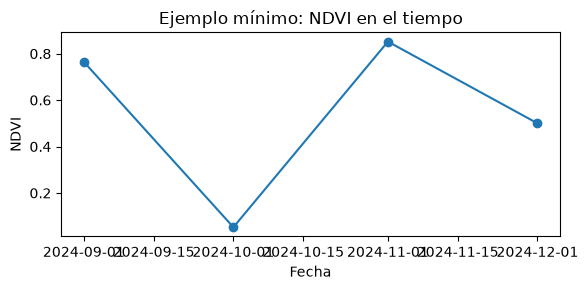

In [9]:
# matplotlib: gráfico de línea de una serie de tiempo
plt.figure(figsize=(6, 3))
plt.plot(df_demo["fecha"], df_demo["ndvi"], marker="o")
plt.title("Ejemplo mínimo: NDVI en el tiempo")
plt.xlabel("Fecha")
plt.ylabel("NDVI")
plt.tight_layout()
plt.show()

## 5. Primer contacto con datos raster

Un **raster** no es solo una imagen: es una **matriz de valores con metadatos** (sistema de coordenadas, tamaño de píxel y extensión). Aquí lo simulamos con numpy; con un archivo real sería:

```python
import rasterio
with rasterio.open("lote.tif") as src:
    banda_nir = src.read(1)   # matriz numpy
    print(src.crs, src.transform, src.width, src.height)
```

El [capítulo 6](https://zelaznog-j.github.io/apuntes/03-teledeteccion/06-procesamiento-raster/) trabaja con archivos reales.

## 6. Práctica guiada: serie de NDVI de un lote

1. Cargar un CSV con fechas y reflectancias medias.
2. Calcular el NDVI en una columna nueva, sin bucles.
3. Filtrar fechas con valores inválidos.
4. Graficar la serie.
5. Visualizar una banda y el NDVI de un raster de muestra.

> **Sobre los datos.** Usamos `lote_reflectancias_v2.csv`, que simula un lote de trigo entre septiembre y enero. Sus valores son coherentes con el [capítulo 3](https://zelaznog-j.github.io/apuntes/03-teledeteccion/03-indices-vegetacion/) (suelo con NDVI ~0,1–0,2; cultivo en pleno desarrollo > 0,8) e incluyen **dos filas sucias a propósito**. Si no tienes el archivo, la celda siguiente lo genera. Para usar tu propio lote, sube tu CSV a Colab y cambia el nombre en el Paso 1.

### Paso 1 — Cargar el CSV

In [10]:
import os
ARCHIVO = "lote_reflectancias_v2.csv"

if not os.path.exists(ARCHIVO):             # si no subiste el archivo, lo generamos
    rng = np.random.default_rng(7)
    fechas = pd.date_range("2024-09-01", "2025-01-15", freq="7D")   # una medición semanal
    n = len(fechas)
    t = np.linspace(0, 1, n)
    curva = np.exp(-((t - 0.55) ** 2) / (2 * 0.18 ** 2))            # forma de campana
    nir = 0.26 + 0.40 * curva + rng.normal(0, 0.015, n)
    red = 0.20 - 0.14 * curva + rng.normal(0, 0.010, n)
    sucio = pd.DataFrame({"fecha": fechas.astype(str), "nir": nir, "red": red})
    sucio.loc[3, ["nir", "red"]] = 0.0       # dato faltante: 0 y 0
    sucio.loc[10, "nir"] = -0.05             # reflectancia negativa, imposible
    sucio.to_csv(ARCHIVO, index=False)
    print("CSV generado:", ARCHIVO)

df = pd.read_csv(ARCHIVO, parse_dates=["fecha"])   # parse_dates: la fecha queda como fecha, no como texto
print(df.dtypes)
df.head()

fecha    datetime64[us]
nir             float64
red             float64
dtype: object


,fecha,nir,red
0,2024-09-01,0.289114,0.215193
1,2024-09-08,0.261804,0.198466
2,2024-09-15,0.279392,0.189514
3,2024-09-22,0.000000,0.000000
4,2024-09-29,0.315727,0.175900


### Paso 2 — Calcular el NDVI (sin bucles)

In [11]:
df["ndvi"] = (df["nir"] - df["red"]) / (df["nir"] + df["red"])
df.head(6)

,fecha,nir,red,ndvi
0,2024-09-01,0.289114,0.215193,0.146580
1,2024-09-08,0.261804,0.198466,0.137611
2,2024-09-15,0.279392,0.189514,0.191676
3,2024-09-22,0.000000,0.000000,NaN
4,2024-09-29,0.315727,0.175900,0.284418
5,2024-10-06,0.372394,0.146166,0.436262


### Paso 3 — Filtrar fechas inválidas

En Python "puro", dividir por cero lanza `ZeroDivisionError`. En numpy y pandas **no**: da `NaN` o `inf` en silencio, así que hay que revisarlo.

El criterio mira la **reflectancia** (debe ser positiva) y el **rango posible del NDVI** (−1 a 1). No descarta NDVI negativos por sí solos: en un lote anegado pueden ser reales; se marcan como sospechosos y se revisan.

In [12]:
invalidas = (
    df["nir"].le(0) | df["red"].le(0)       # reflectancia nula o negativa
    | ~df["ndvi"].between(-1, 1)            # NDVI fuera de rango (también atrapa los NaN)
)
print(f"Fechas inválidas: {invalidas.sum()} de {len(df)}")
df[invalidas]

Fechas inválidas: 2 de 20


,fecha,nir,red,ndvi
3,2024-09-22,0.00,0.000000,NaN
10,2024-11-10,-0.05,0.053781,-27.44701


In [13]:
df_limpio = df[~invalidas].copy()
print(f"Quedan {len(df_limpio)} de {len(df)} fechas.")
print("NDVI mínimo:", df_limpio["ndvi"].min().round(2), "· máximo:", df_limpio["ndvi"].max().round(2))
df_limpio.head()

Quedan 18 de 20 fechas.
NDVI mínimo: 0.14 · máximo: 0.83


,fecha,nir,red,ndvi
0,2024-09-01,0.289114,0.215193,0.146580
1,2024-09-08,0.261804,0.198466,0.137611
2,2024-09-15,0.279392,0.189514,0.191676
4,2024-09-29,0.315727,0.175900,0.284418
5,2024-10-06,0.372394,0.146166,0.436262


### Paso 4 — Graficar la serie

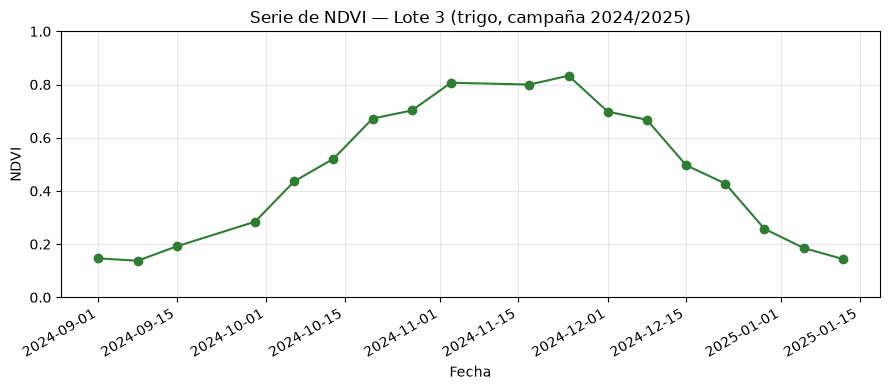

In [14]:
plt.figure(figsize=(9, 4))
plt.plot(df_limpio["fecha"], df_limpio["ndvi"], marker="o", linewidth=1.5, color="#2E7D32")
plt.title("Serie de NDVI — Lote 3 (trigo, campaña 2024/2025)")
plt.xlabel("Fecha")
plt.ylabel("NDVI")
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.gcf().autofmt_xdate()
plt.tight_layout()
plt.show()

### Paso 5 — Visualizar una banda y el NDVI de un raster de muestra

Simulamos un raster de 40 × 40 píxeles con una zona de estrés en una esquina. Con un GeoTIFF real, `nir_raster` y `red_raster` vendrían de `src.read(...)`.

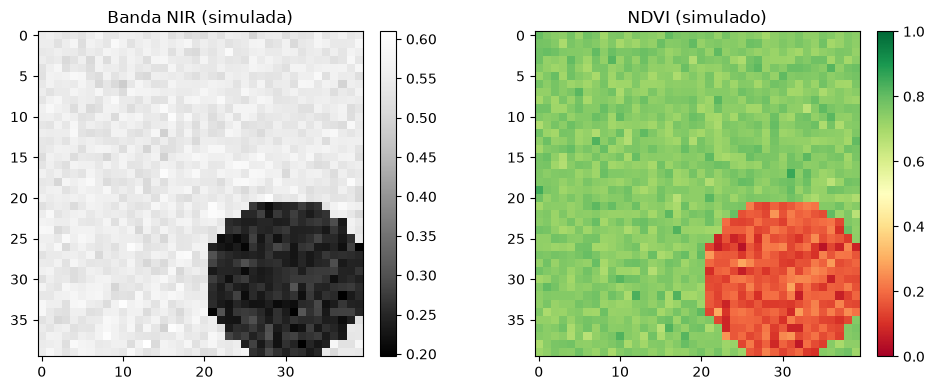

In [15]:
rng = np.random.default_rng(7)
alto, ancho = 40, 40
y, x = np.mgrid[0:alto, 0:ancho]

# Zona de estrés simulada: un círculo en la esquina inferior derecha
distancia = np.sqrt((y - 30) ** 2 + (x - 30) ** 2)
mascara_estres = distancia < 10

nir_raster = np.full((alto, ancho), 0.55) + rng.normal(0, 0.02, (alto, ancho))
red_raster = np.full((alto, ancho), 0.08) + rng.normal(0, 0.01, (alto, ancho))
nir_raster[mascara_estres] -= 0.30     # menos NIR  -> menor vigor
red_raster[mascara_estres] += 0.10     # más rojo   -> menor vigor

ndvi_raster = (nir_raster - red_raster) / (nir_raster + red_raster)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
im0 = axes[0].imshow(nir_raster, cmap="Greys_r")
axes[0].set_title("Banda NIR (simulada)")
fig.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

im1 = axes[1].imshow(ndvi_raster, cmap="RdYlGn", vmin=0, vmax=1)
axes[1].set_title("NDVI (simulado)")
fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

## 7. Cierre e ideas clave

1. Programar no reemplaza a los visores web: los complementa en automatización, reproducibilidad y escala.
2. Variables, listas, diccionarios y funciones bastan para pasar de "ver una imagen" a "procesar datos".
3. numpy, pandas y matplotlib te acompañarán en el resto del libro.
4. Un raster es una matriz con metadatos geoespaciales.
5. Un mensaje de error es información: léelo.

### Errores frecuentes
- Ejecutar celdas fuera de orden.
- Fechas leídas como texto (usa `parse_dates` o `pd.to_datetime`).
- No revisar `NaN` e `inf` después de dividir en numpy o pandas.
- Confundir `/` (división) con `//` (división entera).

### Para ir más allá (opcional)
- Calcula SAVI (`((nir - red) / (nir + red + 0.5)) * 1.5`) sobre `df_limpio` y agrégalo como columna.
- Agrega una segunda zona de estrés al raster simulado.
- Reemplaza el CSV por uno propio y repite los Pasos 1 a 4.

### Avance del proyecto
Sube el contorno de tu lote a Google Drive y crea un **proyecto de Google Cloud registrado para Earth Engine**. Déjalo listo antes del [capítulo 5](https://zelaznog-j.github.io/apuntes/03-teledeteccion/05-acceso-imagenes/).